# 1. házi feladat

Az első házi feladat során egy egyszerű Multi-layer Perceptron (MLP) típusú neuronhálót kell betanítani és kiértékelni egy regressziós és egy klasszifikációs feladaton a PyTorch könyvtár segítségével.

A házi feladat több részfeladatból áll (A - I), melyek egymásra épülnek. A feladat automatikus tesztelőszkripttel rendelkezik és vizsgálja az egyes részfeladatokra adott megoldások helyességét. Éppen ezért, **ne változtasd meg a notebook struktúráját**, ne szedd több részre, illetve ne módosítsd a megírt részeket, csak a megoldásaidat írd be a megfelelő helyre, különben nem fogjuk tudni értékelni! A megoldások az `# Implement your solution BELOW` és `# Implement your solution ABOVE` sorok közé írandók. Ha a megoldott részfeladatok futtatásakor a "Tester: .... OK" felirat megjelenik, _vélhetően_ jó a megoldás. Azonban, a tesztelőszkript nem képes a megoldás helyességét minden aspektus szerint ellenőrizni. Így elképzelhető, hogy beadás után további javításokat kérünk a megoldásban. A beadott házi feladatok gépi tanulás alapú plágiumellenőrzésen esnek át. Másolás gyanújának felmerülése esetén mind a másolat(ok), mind az azt/azokat ihlető eredeti megoldások visszautasíthatók.


Tesztelő szkript letöltése, importok.

In [115]:
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt

from StudentData_MLP_Tester import Tester

--2026-04-04 15:21:47--  http://nipg12.inf.elte.hu/~vavsaai@nipg.lab/annbsc26_p1/files/annbsc26_p1_hw1_tester.py
Resolving nipg12.inf.elte.hu (nipg12.inf.elte.hu)... 157.181.160.172
Connecting to nipg12.inf.elte.hu (nipg12.inf.elte.hu)|157.181.160.172|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14743 (14K)
Saving to: ‘annbsc26_p1_hw1_tester.py’

annbsc26_p1_hw1_tes 100%[===================>]  14.40K  --.-KB/s    in 0.1s    

2026-04-04 15:21:47 (129 KB/s) - ‘annbsc26_p1_hw1_tester.py’ saved [14743/14743]



###**A**: Az adatbázis betöltése

**Információ az adatbázisról**:
Az adatbázis eredetije az UCI Machine Learning Repository-ról származik (http://archive.ics.uci.edu/ml/datasets/Student+Performance), mely kissé módosítva lett. Két portugál középiskolában tanuló diákok néhány adatát és a harmadév végi, év végi jegyeiket (0-20) tartalmazza. A házi feladat keretében, **neuronhálókkal próbálunk a diákok szociális és pénzügyi háttere alapján becsléseket adni az iskolai teljesítményükre.**

A tesztelőszkript letölti a szöveges formában tárolt adatbázist és elhelyezi a `content` sztringben. Alább, kiírjuk a hosszát és az első 500 karaktert is a sztringből. Az adatbázis fájlok egy-egy sora adja meg az egy-egy mintaelemhez tartozó változók értékeit. A sorokban az egyes változókhoz tartozó értékek pontosvesszővel vannak elválasztva. Az adatbázis első sora a változók neveit tartalmazza.

A feladatod, hogy **alakítsd át a `content` sztringet az adatbázis változóinak értékeit tartalmazó NumPy tömbbé.** A tömbök adattípusa np.float32 (lebegőpontos) legyen! A változók értékeit helyezd el a `dataset_noisy` (n_mintaelem, n_változó) alakú tömbben!  Az input változókat és címkéket később választjuk majd szét.

Az adatbázis helyenként hiányzó értékeket tartalmaz: az adatok egy része nem volt elérhető az adatbázis rögzítésekor. Konkrétabban, a szülők munkáját leíró és a tanuló gyámjának kilétére vonatkozó oszlopokban találhatók hiányzó értékek. Ezek a kilencedik (Mjob), tizedik (Fjob) és tizenkettedik (guardian) oszlopokban találhatók. Hiányzó értékek esetén a `content` sztringben ténylegesen is hiányoznak a megfelelő pontosvesszők közt elhelyezkedő értékek, tehát ilyenkor két (vagy több) pontosvessző következik egymás után.

A hiányzó értékeket kezelned kell és fel kell ismerned beolvasás közben: a hiányzó értékek helyére a `dataset_noisy` tömbben `np.nan` (Not-a-Number) értékek kell, hogy kerüljenek!

In [116]:
tester = Tester()
content = tester.get_dataset_content()

print("Number of characters in dataset:", len(content))
print(content[:500])


Number of characters in dataset: 27418
school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3
0;0;18;0;1;1;4;4;5;0;4;;2;2;0;0;1;1;1;0;0;1;1;4;3;4;1;1;3;6;14;15;15
0;0;17;0;1;0;1;1;5;3;4;1;1;2;0;1;0;1;1;1;0;0;1;5;3;3;1;1;3;4;6;6;7
0;0;15;0;0;0;1;1;5;;3;;1;2;3;0;1;0;1;0;0;0;1;4;3;2;2;3;3;10;7;7;8
0;0;15;0;1;0;4;2;1;4;0;;1;3;0;1;0;0;0;0;0;0;0;3;2;2;1;1;5;2;15;15;15
0


In [117]:
# implement your solution BELOW
dataset = []

lines = content.strip().split('\n')
lines_segmented = [line.split(';') for line in lines]
data = lines_segmented[1:]


for rec in data:
  data_row=[]
  for d in rec:
    d = d.strip()
    val = float('nan') if d == '' else float(d)
    data_row.append(val)
  dataset.append(data_row)

print(dataset[:5])
dataset_noisy = np.array(dataset, dtype=np.float32)
print(dataset_noisy[:5])


# implement your solution ABOVE

tester.test('dataset_load', dataset_noisy)

[[0.0, 0.0, 18.0, 0.0, 1.0, 1.0, 4.0, 4.0, 5.0, 0.0, 4.0, nan, 2.0, 2.0, 0.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 4.0, 3.0, 4.0, 1.0, 1.0, 3.0, 6.0, 14.0, 15.0, 15.0], [0.0, 0.0, 17.0, 0.0, 1.0, 0.0, 1.0, 1.0, 5.0, 3.0, 4.0, 1.0, 1.0, 2.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 5.0, 3.0, 3.0, 1.0, 1.0, 3.0, 4.0, 6.0, 6.0, 7.0], [0.0, 0.0, 15.0, 0.0, 0.0, 0.0, 1.0, 1.0, 5.0, nan, 3.0, nan, 1.0, 2.0, 3.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 4.0, 3.0, 2.0, 2.0, 3.0, 3.0, 10.0, 7.0, 7.0, 8.0], [0.0, 0.0, 15.0, 0.0, 1.0, 0.0, 4.0, 2.0, 1.0, 4.0, 0.0, nan, 1.0, 3.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.0, 2.0, 2.0, 1.0, 1.0, 5.0, 2.0, 15.0, 15.0, 15.0], [0.0, 0.0, 16.0, 0.0, 1.0, 0.0, 3.0, 3.0, 3.0, 3.0, 0.0, 1.0, 1.0, 2.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0, 4.0, 3.0, 2.0, 1.0, 2.0, 5.0, 4.0, 13.0, 14.0, 14.0]]
[[ 0.  0. 18.  0.  1.  1.  4.  4.  5.  0.  4. nan  2.  2.  0.  0.  1.  1.
   1.  0.  0.  1.  1.  4.  3.  4.  1.  1.  3.  6. 14. 15. 15.]
 [ 0.  0. 17

## **B**: A hiányzó adat kezelése

NaN értékekkel nem fogunk tudni tovább dolgozni, hiszen a legtöbb NumPy/PyTorch művelet nem támogatja őket és bármilyen tömbre, melyben legalább egy NaN érték található, ezen műveletek kimenete is NaN lesz, így például a neuronhálónk becslése és költsége is. Utóbbi megakadályozza, hogy a hálót gradiens módszerrel optimalizáljuk. Éppen ezért, a hiányzó adatokat reprezentáló NaN értékeket az alábbi módon fogjuk eltüntetni:

**Hozz létre minden NaN értéket tartalmazó változóhoz egy-egy újabb változót, melyek azt jelzik, hogy valódi érték található-e az adott változóban az adott mintaelemnél, vagy nem!** Valódi érték esetén az új változó kapjon 1 értéket, NaN esetén pedig 0 értéket! Helyezd el az eredeti adatot és az új változókat a `dataset` tömbben: az új változók oszlopai kerüljenek megfelelő sorrendben az összes eredeti változót tartalmazó oszlop **után**! Az előző feladat leírásában említésre került, hogy melyik oszlopok tartalmazhatnak NaN értékeket.</br>
Mivel a 33 változós adatbázisunk #8, #9 és #11 indexű oszlopai (változói) tartalmazhatnak NaN értékeket, akkor az új `dataset` tömbünk 36 változós lesz és a három új változó az utolsó három oszlopba kerül. Például tehát, a #33 indexű oszlopban egy adott sorba nullás érték kerül, ha a #8-as oszlopban annál a sornál NaN található, egyébként pedig 1-es érték kerül oda. Hasonlóan készítjük el a #34, #35 indexű oszlopokat a #9 és #11 indexű oszlopok alapján.

Végül, **helyettesítsd** az így elkészült **tömb összes NaN értékét nullával!**


In [118]:
# implement your solution BELOW

new_coloumns = (~np.isnan(dataset_noisy)[:,[8,9,11]]).astype(np.float32)
print(new_coloumns)
dataset = np.concatenate((dataset_noisy, new_coloumns), axis=1)
dataset[np.isnan(dataset)] = 0.0

# implement your solution ABOVE

tester.test('dataset_fill_missing', dataset)

[[1. 1. 0.]
 [1. 1. 1.]
 [1. 0. 0.]
 ...
 [1. 1. 1.]
 [1. 1. 0.]
 [1. 0. 1.]]
Tester: Dataset fill missing OK


## **C**: Tanító-, validációs- és teszthalmaz szétválasztása

**Keverd meg véletlenszerűen a mintaelemeket** a `dataset` tömbben! Ezt általánosságban azért célszerű megtenni, mert az adatbázisban az elemek valamilyen tulajdonságaik alapján rendezve lehetnek. Megkeverés nélkül, a szétválasztott halmazokban jelentősen különbözne a címkék eloszlása.

Ezt követően **válaszd szét a tömböt tanító-, validációs- és teszthalmazra**, 50%, 25%, 25% arányban! A halmazokat tartalmazó három tömböt nevezd el `dataset_split_train`, `dataset_split_val`, `dataset_split_test`-nek, sorrendben!

In [119]:
# implement your solution BELOW

dataset_shuffled = np.random.permutation(dataset)

n_training_samples = int(dataset_shuffled.shape[0] * 0.5)
n_validation_samples = int(dataset_shuffled.shape[0] * 0.25)
validation_offset = n_training_samples
test_offset = n_training_samples + n_validation_samples

dataset_split_train = dataset_shuffled[:validation_offset, :]
dataset_split_val = dataset_shuffled[validation_offset:test_offset,:]
dataset_split_test = dataset_shuffled[test_offset:, :]


# implement your solution ABOVE

tester.test('dataset_split', dataset_split_train, dataset_split_val, dataset_split_test)

Tester: Dataset split OK


## **D**: Az adat-iterátorok létrehozása a regressziós feladathoz

A neuronhálók gradiens módszeres betanítását a legtöbbször iterátorokkal valósítjuk meg, melyek bejárják az adatbázisunkat és előállítják a neuronhálók tanításához szükséges input és címke kötegeket. A regressziós feladat során a becsülendő címkeváltozó a diákok év végi jegye lesz (`G3` nevű oszlop az eredeti adatbázis szövegfájlban - ez a 32-es indexű oszlop), míg az input változókat az összes többi attribútum adja, beleértve az újonnan előállított három változót is.

Ebben a részfeladatban **elő kell állítanod három iterátor objektumot** `dataloader_reg_train`, `dataloader_reg_val`, `dataloader_reg_test` néven, melyek az előző részfeladatban elkészített tanító-, validációs- és teszthalmazokat tartalmazó tömböket járják be. **Az iterátorok minden lépésben két tenzort adnak vissza**, melyek egy-egy kötegnyi input és címke adatot tárolnak el. A visszaadott tenzorok alakja tehát `(batch_size, 35)` és `(batch_size, 1)` lesz. Utóbbi (a címkéket tartalmazó tenzor) a diákok év végi jegyeit fogja tartalmazni, előbbi pedig az adatbázis összes többi változójának értékét a megfelelő mintaelemekre. `batch_size` a mintaelemek számát adja meg, melyeket egyszerre, egy kötegben fog megkapni a neuronhálónk - ennek értéke lehet például 32.

Hangsúlyozandó, hogy az iterátorok a fent említett NumPy tömbökből (`np.ndarray`) nyert mintaelem-kötegeket már `torch.tensor` típusú objektumokként adják vissza (pontosabban, kételemű tuple-öket adnak vissza, melyekben `torch.tensor` objektumok lesznek). A PyTorch-al definiált neuronhálók betanításához már mindenképp PyTorch tenzorok szükségesek. A tenzorok **adattípusa** 4 bájtos lebegőpontos típus (`torch.float32`) legyen!

A **tanító és validációs halmazt felsoroló iterátorok járják be véletlen sorrendben** a hozzájuk tartozó mintaelemeket! A teszt halmazt felsoroló iterátor ne változtasson a `dataset_split_test` tömb sorrendjén!

Az iterátorok implementációja többféleképpen megoldható. Például, egyedi generátorral/iterátorral, vagy a `torch.utils.data` modul `Dataset` és `DataLoader` osztályai felhasználásával és esetleges származtatásával.

In [120]:
# implement your solution BELOW

class RegressionDataset(Dataset):
  def __init__(self, input_split, labels_split):
    self.xs = torch.tensor(input_split, dtype=torch.float32)
    self.ys = torch.tensor(labels_split, dtype=torch.float32)

  def __len__(self):
    return self.xs.shape[0]

  def __getitem__(self, idx):
    return self.xs[idx, :], self.ys[idx, None]

inputs_train = np.concatenate((dataset_split_train[:,:32],dataset_split_train[:,33:]), axis=1)
labels_train = dataset_split_train[:,32]

inputs_val = np.concatenate((dataset_split_val[:,:32],dataset_split_val[:,33:]), axis=1)
labels_val = dataset_split_val[:,32]

inputs_test = np.concatenate((dataset_split_test[:,:32],dataset_split_test[:,33:]), axis=1)
labels_test = dataset_split_test[:,32]

train_dataset = RegressionDataset(inputs_train, labels_train)
val_dataset = RegressionDataset(inputs_val, labels_val)
test_dataset = RegressionDataset(inputs_test, labels_test)

dataloader_reg_train = DataLoader(train_dataset, batch_size=32, shuffle=True)
dataloader_reg_val = DataLoader(val_dataset, batch_size=32, shuffle=True)
dataloader_reg_test = DataLoader(test_dataset, batch_size=32, shuffle=False)

# implement your solution ABOVE

tester.test('reg_iter', dataloader_reg_train, dataloader_reg_val, dataloader_reg_test)

Tester: Dataset iterators for regression task OK


## **E**: A regressziós neuronháló definiálása

**Definiáld a regressziós feladathoz alkalmazandó neuronhálót megvalósító osztályt**, mely az általános `torch.nn.Module` osztály leszármazottja, majd példányosítsd azt és add értékül a `reg_model` nevű változónak a példányt!

A regressziós neuronháló **tartalmazzon 3 teljesen összekötött réteget, sorban 25, 25 és 1 neuronnal és alkalmazza a ReLU aktivációs függvényt a rétegek között!**

Az új osztálynak mindenképpen meg kell valósítania a `forward(self, x)` tagfüggvényt, mely a neuronhálót (hipotézisfüggvényt) az `x` input tenzorra kiértékeli. A `forward` függvény fogja majd az előbb definiált adat-iterátorból érkező input tenzorokat megkapni és előállítani belőle a címkebecsléseket. Az osztály konstruktorában célszerű a neuronhálónk rétegeit inicializálni.

In [121]:
# implement your solution BELOW

class RegModel(nn.Module):
  def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(   # option#1 put all layers/operations into a Sequential (nn.Module subclass type)
            nn.Linear(35, 25),
            nn.ReLU(),
            nn.Linear(25, 25),
            nn.ReLU(),
            nn.Linear(25, 1)
        )


  def forward(self, x):
      return self.layers(x)

reg_model = RegModel()

# implement your solution ABOVE

tester.test('reg_model_architecture', reg_model)

Tester: Regression model architecture OK


## **F**: A háló betanítása regressziós feladatra

**Tanítsd be a** `reg_model` **neuronhálót** a tanítóhalmazon a `dataloader_reg_train` iterátor segítségével és alkalmazd a `dataloader_reg_val` iterátort a validációhoz! Az iterátorok egyetlen (akár véletlen sorrendben történő) végighaladása a tanító és validációs adathalmazokon határoz meg egy _epoch_-ot.

Alkalmazd a regressziókor szokásosan használt **"átlagos négyzetes eltérés" költséget**! **Mérd le minden epoch-ban a tanító- és a validációs halmazon mért költségeket, majd a tanítás végeztével rajzold ki ezeknek az értékeknek a tanítás során való alakulását egy közös grafikonon!** A grafikonok kirajzolásához használhatod például a `matplotlib` könyvtárat. Figyelj rá, hogy a grafikonon jól látszódjanak a görbék közti eltérések a tanítás végén is! Ha szükséges, beállíthatod ehhez kézzel, hogy az y tengely melyik részét mutassa a grafikon. **A grafikonon legyen jelmagyarázat** (legend), mely megmutatja, melyik görbe írja le a tanítási költséget és melyik a validációs költséget!

Azt, hogy a tanítás meddig tartson (az epoch-ok számát) megadhatod kézzel is, a validációs költség alakulása alapján: próbáld úgy megadni, hogy a neuronháló lehetőleg jól betanult legyen, de súlyos túltanulás még ne jelenjen meg!

A betanításhoz válassz egy gradiens módszer alapú **optimalizációs algoritmust** a `torch.optim` modulból (pl. `SGD`, `Adam`, `RMSprop`, stb.), majd válassz egy megfelelő **tanulási rátát** is!

A betanítás végeztével **mérd le az átlagos költséget a teljes teszthalmazon** és add értékül a kapott számot a `test_mse` változónak!

Ezt követően, **válassz néhány mintaelemet a teszthalmazból** (például a `dataloader_reg_test` iterátor segítségével) és **adj becslést a címkéjükre** az input változók értékei alapján, majd **írasd ki az egyes mintaelemekre a becsült és az igazi címkéjüket!** Így példákon is láthatjuk, hogy mennyire ad jó becsléseket a neuronhálónk.



Epoch #0, tr loss: 141.4492645263672, val loss: 121.55856323242188
    Early stopping: Best model updated.
Epoch #1, tr loss: 143.41697692871094, val loss: 108.18592834472656
    Early stopping: Best model updated.
Epoch #2, tr loss: 121.64618682861328, val loss: 113.00437927246094
Epoch #3, tr loss: 103.46331787109375, val loss: 75.71920776367188
    Early stopping: Best model updated.
Epoch #4, tr loss: 78.24649810791016, val loss: 58.116676330566406
    Early stopping: Best model updated.
Epoch #5, tr loss: 60.889591217041016, val loss: 40.4022216796875
    Early stopping: Best model updated.
Epoch #6, tr loss: 36.461151123046875, val loss: 23.964088439941406
    Early stopping: Best model updated.
Epoch #7, tr loss: 18.66642951965332, val loss: 15.622003555297852
    Early stopping: Best model updated.
Epoch #8, tr loss: 12.123997688293457, val loss: 14.773359298706055
    Early stopping: Best model updated.
Epoch #9, tr loss: 11.658787727355957, val loss: 10.921987533569336
    Ea

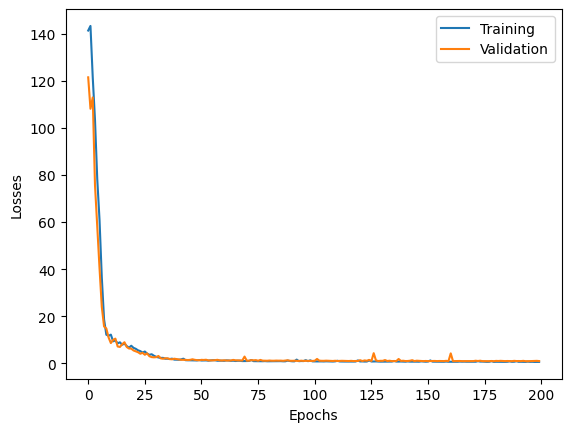

1 - Prediction: 16.10 | Real data: 16.00
2 - Prediction: 8.82 | Real data: 8.00
3 - Prediction: 10.94 | Real data: 11.00
4 - Prediction: 17.09 | Real data: 17.00
5 - Prediction: 10.30 | Real data: 13.00
Tester: Regression model learning OK


In [122]:
# implement your solution BELOW

#convert from numpy array to torch tensors
inputs_train_t = torch.tensor(inputs_train, dtype=torch.float32)
inputs_val_t = torch.tensor(inputs_val, dtype=torch.float32)
inputs_test_t = torch.tensor(inputs_test, dtype=torch.float32)
labels_train_t = torch.tensor(labels_train, dtype=torch.float32)
labels_val_t = torch.tensor(labels_val, dtype=torch.float32)
labels_test_t = torch.tensor(labels_test, dtype=torch.float32)

loss_fn = nn.MSELoss() #quadratic loss

n_max_epochs = 200
learning_rate = 0.001
batch_size = 32
optimizer = torch.optim.Adam(reg_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []

best_reg_model = None
best_val_loss = float('inf')
early_stopping_patience = 40
last_early_stopping_update_ep_idx = 0

for epoch_idx in range(n_max_epochs):

    #training mode
    reg_model.train()
    train_losses_in_epoch = []

    for train_batch_xs, train_batch_ys in dataloader_reg_train:
        optimizer.zero_grad()
        train_batch_ys_pred = reg_model(train_batch_xs)
        loss = loss_fn(train_batch_ys_pred, train_batch_ys)
        train_losses_in_epoch.append(loss.detach())
        loss.backward()
        optimizer.step()

    train_losses_in_epoch = torch.tensor(train_losses_in_epoch)
    avg_tr_epoch_loss = train_losses_in_epoch.mean()
    train_losses.append(avg_tr_epoch_loss)

    #evaluation mode
    reg_model.eval()
    val_losses_in_epoch = []

    for val_batch_xs, val_batch_ys in dataloader_reg_val:

        with torch.no_grad():
            val_batch_ys_pred = reg_model(val_batch_xs)
            loss = loss_fn(val_batch_ys_pred, val_batch_ys)
            val_losses_in_epoch.append(loss)


    val_losses_in_epoch = torch.tensor(val_losses_in_epoch)
    avg_val_epoch_loss = val_losses_in_epoch.mean()
    val_losses.append(avg_val_epoch_loss)

    print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}")

    #early stopping
    if avg_val_epoch_loss < best_val_loss:
        best_val_loss = avg_val_epoch_loss
        best_reg_model = copy.deepcopy(reg_model)
        last_early_stopping_update_ep_idx = epoch_idx
        print("    Early stopping: Best model updated.")

    # early stopping: break if no update for a long time
    if last_early_stopping_update_ep_idx + early_stopping_patience < epoch_idx:
        print("Training is terminated by early stopping.")
        break

print("Training finished. Best model weights are restored.")
reg_model = best_reg_model

#Testing phase
test_ys_preds = []
for test_batch_xs, test_batch_ys in dataloader_reg_test:
    with torch.no_grad():                            # no need to compute gradients for validation predictions/losses
        test_batch_ys_pred = reg_model(test_batch_xs)
        test_ys_preds.append(test_batch_ys_pred)     # not collecting losses, but all predictions
                                                     # test_batch_ys_pred.detach() is not needed, again, as we are in a no_grad environment

test_ys_preds = torch.cat(test_ys_preds, dim=0)
test_mse = loss_fn(test_ys_preds, labels_test_t[:,None]).item()

print(f"Test loss: {test_mse}")

#Graph
plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.xlabel('Epochs')
plt.ylabel('Losses')
plt.legend()
plt.show()


#Examples
for i in range(5):
    prediction = test_ys_preds[i].item()
    real = labels_test_t[i].item()
    print(f"{i+1} - Prediction: {prediction:.2f} | Real data: {real:.2f}")

# implement your solution ABOVE

tester.test('reg_model_learning', test_mse)

## **G**: Az adat-iterátorok létrehozása a klasszifikációs feladathoz

Hasonlóan a D) feladathoz, itt is három adat-iterátort kell létrehoznunk, azonban ezúttal egy kissé eltérő feladatot fogunk megtanulni megoldani, így a visszaadott tenzorok alakja / adattípusa is eltérő lesz. **Állítsd elő** a `dataloader_cl_train`, `dataloader_cl_val`, `dataloader_cl_test` nevű **iterátorokat**, melyek ugyancsak a C) részfeladatban elkészült tanító-, validációs- és teszthalmazokat tartalmazó tömböket járják be! A klasszifikációs feladatban input változókként az összes változót felhasználjuk az adatbázisban, kivéve a három harmadév végi jegyét a diákoknak (`G1`, `G2`, `G3` nevű, #30, #31 és #32 indexű oszlopok az eredeti adatbázis szövegfájlban). Címkeként három kategóriát definiálunk és az összes diákot besoroljuk ezekbe a kategóriákba:
- **"Gyengén teljesítő diákok"** kategória, #0 kategóriaindex: azon diákok kerülnek ide, akiknek legalább két jegyük kisebb, mint 11.
- **"Közepesen teljesítő diákok"** kategória, #1 kategóriaindex: azon diákok kerülnek ide, akik átlagos jegye kisebb, mint 14, de nem tartoznak a "Gyengén teljesítő diákok" közé.
- **"Jól teljesítő diákok"** kategória, #2 kategóriaindex: azon diákok kerülnek ide, akik nem tartoznak a másik két kategóriába.

A fentiek alapján az iterátorok által visszaadott tenzorok alakja `(batch_size, 33)` és `(batch_size,)` lesz. Utóbbi (a címkéket tartalmazó tenzor) a diákok kategóriaindexét fogja tartalmazni (azaz 0, 1, vagy 2 értékeket, `torch.int64` adattípusban), előbbi pedig az adatbázis összes felhasznált változójának értékét a megfelelő mintaelemekre `torch.float32` adattípusban. `batch_size` ezúttal is a mintaelemek számát adja meg, ez kézzel beállítandó.

A **tanító és validációs halmazt felsoroló iterátorok véletlen sorrendben járják be** a hozzájuk tartozó mintaelemeket! A teszt halmazt felsoroló iterátor ne változtasson a `dataset_split_test` tömb sorrendjén!

In [123]:
# implement your solution BELOW

class MultiClassificationDataset(Dataset):
  def __init__(self, input_split, labels_split):
    self.xs = torch.tensor(input_split, dtype=torch.float32)
    self.ys = torch.tensor(labels_split, dtype=torch.int64)

  def __len__(self):
    return self.xs.shape[0]

  def __getitem__(self, idx):
    return self.xs[idx], self.ys[idx]

inputs_train = np.delete(dataset_split_train, [30, 31, 32], axis=1)
grades = dataset_split_train[:,[30,31,32]]
labels_train = np.where(np.count_nonzero(grades < 11, axis=1) > 1, 0, np.where(np.average(grades, axis=1) < 14, 1, 2))

inputs_val = np.delete(dataset_split_val, [30, 31, 32], axis=1)
grades = dataset_split_val[:,[30,31,32]]
labels_val = np.where(np.count_nonzero(grades < 11, axis=1) > 1, 0, np.where(np.average(grades, axis=1) < 14, 1, 2))

inputs_test = np.delete(dataset_split_test, [30, 31, 32], axis=1)
grades = dataset_split_test[:,[30,31,32]]
labels_test = np.where(np.count_nonzero(grades < 11, axis=1) > 1, 0, np.where(np.average(grades, axis=1) < 14, 1, 2))

train_dataset = MultiClassificationDataset(inputs_train, labels_train)
val_dataset = MultiClassificationDataset(inputs_val, labels_val)
test_dataset = MultiClassificationDataset(inputs_test, labels_test)

dataloader_cl_train = DataLoader(train_dataset, batch_size=32, shuffle=True)
dataloader_cl_val = DataLoader(val_dataset, batch_size=32, shuffle=True)
dataloader_cl_test = DataLoader(test_dataset, batch_size=32, shuffle=False)


# implement your solution ABOVE

tester.test('cl_iter', dataloader_cl_train, dataloader_cl_val, dataloader_cl_test)

Tester: Dataset iterators for classification task OK


## **H**: A klasszifikációs neuronháló definiálása

**Definiáld a klasszifikációs feladathoz alkalmazandó neuronhálót megvalósító osztályt**, mely a regressziós neuronhálót implementáló osztályhoz hasonlóan, az általános `torch.nn.Module` osztály leszármazottja! Példányosítsd az új osztályt és add értékül a `cl_model` nevű változónak a példányt!

A klasszifikációs neuronháló **tartalmazzon 3 teljesen összekötött réteget! Az első kettő réteg tartalmazzon egyenként 30 és 20 neuront és alkalmazza a ReLU aktivációs függvényt a rétegek után!** Az utolsó réteget a háromkategóriás klasszifikációnak megfelelően kell kialakítani!

In [124]:
# implement your solution BELOW

class MultiClassifierModel(nn.Module):

  def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(   # option#1 put all layers/operations into a Sequential (nn.Module subclass type)
            nn.Linear(33, 30),
            nn.ReLU(),
            nn.Linear(30, 20),
            nn.ReLU(),
            nn.Linear(20, 3),
        )

  # Regression: no activation function at end
  # Binary classification: Sigmoid at end
  # Multi-class classification: no activation function at end ONLY IN PYTORCH (Softmax is included in CELoss)

  def forward(self, x):
      return self.layers(x)


cl_model = MultiClassifierModel()

# implement your solution ABOVE

tester.test('cl_model_architecture', cl_model)

Tester: Classification model architecture OK


## **I**: A háló betanítása (multi-class) klasszifikációs feladatra

**Tanítsd be a** `cl_model` **neuronhálót** a tanítóhalmazon a `dataloader_cl_train` iterátor segítségével és alkalmazd a `dataloader_cl_val` iterátort a validációhoz!

Alkalmazd a multi-class klasszifikációkor szokásosan használt **cross-entropy költséget**! **Mérd le minden epoch-ban a tanító- és a validációs halmazon mért költségeket, majd a tanítás végeztével rajzold ki ezeknek az értékeknek a tanítás során való alakulását egy közös grafikonon!** A grafikonon a jelmagyarázat meglétére és a görbék könnyű elkülöníthetőségére figyelj ezúttal is!

A tanítást ezúttal az **early stopping** technika állítsa le! Amennyiben adott számú epoch-on keresztül (`patience`) nem javul a validációs költség, érjen véget a betanítás és **állítsuk vissza a `cl_model` súlyait abból az epoch-ból, amikor a legjobb volt a validációs költség!** Mindez automatikusan történjen!

A betanítás végeztével **mérd le az átlagos költséget a teljes teszthalmazon** és add értékül a kapott számot a `test_ce` változónak!

**Számold ki az _accuracy_ (pontosság) metrikát is a teszthalmaz elemein** és add értékül a kapott számot a `test_acc` változónak!! Az _accuracy_ metrika a helyesen klasszifikált mintaelemek arányát adja meg. Például, ha 150 mintaelem kategóriájának becslésekor 75 esetben találtuk el a helyes kategóriát, az _accuracy_ értéke 0.5 lesz.

Ezt követően, **válassz néhány mintaelemet a teszthalmazból** (például a `dataloader_cl_test` iterátor segítségével) és **adj becslést a címkéjükre** (a kategória indexére) az input változók értékei alapján, majd **írasd ki az egyes mintaelemekre a becsült és az igazi címkéjüket** (a kategóriák indexét)! Így példákon is láthatjuk, hogy mennyire ad jó becsléseket a neuronhálónk.

Végezetül, **számold ki a háló teszthalmazon vett konfúziós mátrixát és rajzold ki azt**! A konfúziós mátrix egy k x k méretű mátrix k kategória esetén, ahol az `[i,j]` indexű elem megadja, hogy az adathalmazon a modellünk hány `i` kategóriába tartozó mintaelemet becsült a `j` kategóriába. A modellünk jó teljesítményét jelzi, ha minél több elem kerül a konfúziós mátrix főátlójába. A számoláshoz felhasználhatsz külső könyvtárat is, de NumPy-ban is megoldható. A kirajzoláshoz használható például a `matplotlib.pyplot` csomag `imshow` függvénye. Figyelj rá, hogy a grafikonon világosan látszon, hogy melyik tengely sorolja fel az igazi kategóriákat és melyik a becsült kategóriákat, látszanak a sorok és oszlopok végén a kategóriák indexei és a cellákban az odatartozó mintaelemek darabszáma!


Epoch #0, tr loss: 1.1080065965652466, val loss: 1.1193034648895264, tr acc: 0.2857142984867096, val acc: 0.2578125
    Early stopping: Best model updated.
Epoch #1, tr loss: 1.0483191013336182, val loss: 0.9320333003997803, tr acc: 0.48303571343421936, val acc: 0.6171875
    Early stopping: Best model updated.
Epoch #2, tr loss: 0.9752300977706909, val loss: 0.895378589630127, tr acc: 0.5723214149475098, val acc: 0.5390625
    Early stopping: Best model updated.
Epoch #3, tr loss: 0.8825783729553223, val loss: 0.848703145980835, tr acc: 0.6008929014205933, val acc: 0.6796875
    Early stopping: Best model updated.
Epoch #4, tr loss: 0.8090839982032776, val loss: 0.8600966930389404, tr acc: 0.6258928179740906, val acc: 0.546875
Epoch #5, tr loss: 0.7459832429885864, val loss: 0.7444356679916382, tr acc: 0.6276785731315613, val acc: 0.6640625
    Early stopping: Best model updated.
Epoch #6, tr loss: 0.7177750468254089, val loss: 0.7536298036575317, tr acc: 0.6500000357627869, val acc: 

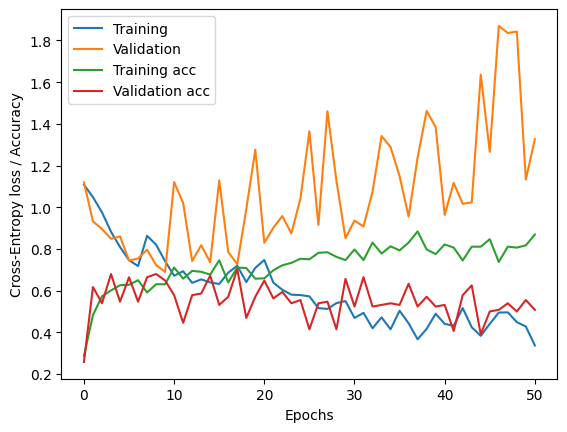

1 - Prediction: 2 | Real data: 2
2 - Prediction: 0 | Real data: 0
3 - Prediction: 1 | Real data: 1
4 - Prediction: 2 | Real data: 2
5 - Prediction: 1 | Real data: 1


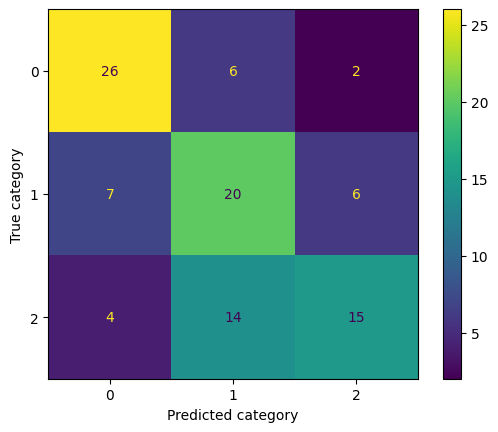

Tester: Classification model learning OK


In [125]:
# implement your solution BELOW

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

inputs_train_t = torch.tensor(inputs_train, dtype=torch.float32)
inputs_val_t = torch.tensor(inputs_val, dtype=torch.float32)
inputs_test_t = torch.tensor(inputs_test, dtype=torch.float32)
labels_train_t = torch.tensor(labels_train, dtype=torch.long)
labels_val_t = torch.tensor(labels_val, dtype=torch.long)
labels_test_t = torch.tensor(labels_test, dtype=torch.long)

def multi_acc_fn(y_hat, y_true):
    preds = torch.argmax(y_hat, dim=1)
    return torch.count_nonzero(preds == y_true) / y_hat.shape[0]

loss_fn = nn.CrossEntropyLoss()

n_max_epochs = 250
learning_rate = 0.01
optimizer = torch.optim.Adam(cl_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []
best_cl_model = None
best_val_loss = float('inf')
early_stopping_patience = 40
last_early_stopping_update_ep_idx = 0

for epoch_idx in range(n_max_epochs):

    # training
    cl_model.train()
    train_losses_in_epoch = []
    train_accs_in_epoch = []

    for train_batch_xs, train_batch_ys in dataloader_cl_train:

        optimizer.zero_grad()
        train_batch_ys_pred = cl_model(train_batch_xs)
        loss = loss_fn(train_batch_ys_pred, train_batch_ys)
        acc = multi_acc_fn(train_batch_ys_pred, train_batch_ys)

        train_losses_in_epoch.append(loss.detach())
        train_accs_in_epoch.append(acc)
        loss.backward()
        optimizer.step()

    train_losses_in_epoch = torch.tensor(train_losses_in_epoch)
    train_accs_in_epoch = torch.tensor(train_accs_in_epoch)
    avg_tr_epoch_loss = train_losses_in_epoch.mean()
    avg_tr_epoch_acc = train_accs_in_epoch.mean()
    train_losses.append(avg_tr_epoch_loss)
    train_accuracy.append(avg_tr_epoch_acc)

    cl_model.eval()
    val_losses_in_epoch = []
    val_accs_in_epoch = []

    for val_batch_xs, val_batch_ys in dataloader_cl_val:

        with torch.no_grad():
            val_batch_ys_pred = cl_model(val_batch_xs)
        loss = loss_fn(val_batch_ys_pred, val_batch_ys)
        acc = multi_acc_fn(val_batch_ys_pred, val_batch_ys)

        val_losses_in_epoch.append(loss)
        val_accs_in_epoch.append(acc)

    val_losses_in_epoch = torch.tensor(val_losses_in_epoch)
    val_accs_in_epoch = torch.tensor(val_accs_in_epoch)
    avg_val_epoch_loss = val_losses_in_epoch.mean()
    avg_val_epoch_acc = val_accs_in_epoch.mean()
    val_losses.append(avg_val_epoch_loss)
    val_accuracy.append(avg_val_epoch_acc)

    # logging
    print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")

    # early stopping
    if avg_val_epoch_loss < best_val_loss:
        best_val_loss = avg_val_epoch_loss
        best_cl_model = copy.deepcopy(cl_model)
        last_early_stopping_update_ep_idx = epoch_idx
        print("    Early stopping: Best model updated.")

    # early stopping: break if no update for a long time
    if last_early_stopping_update_ep_idx + early_stopping_patience < epoch_idx:
        print("Training is terminated by early stopping.")
        break

print("Training finished. Best model weights are restored.")
cl_model = best_cl_model

test_ys_preds = []
for test_batch_xs, test_batch_ys in dataloader_cl_test:
    with torch.no_grad():
        test_batch_ys_pred = cl_model(test_batch_xs)
        test_ys_preds.append(test_batch_ys_pred)

test_ys_preds = torch.cat(test_ys_preds, dim=0)
test_ce = loss_fn(test_ys_preds, labels_test_t)
test_acc = multi_acc_fn(test_ys_preds, labels_test_t)

print(f"Test loss: {test_ce}, test acc: {test_acc}")

plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('Cross-Entropy loss / Accuracy')
plt.legend()
plt.show()


predicted_classes = torch.argmax(test_ys_preds, dim=1)
for i in range(5):
    prediction = predicted_classes[i].item()
    real = labels_test_t[i].item()
    print(f"{i+1} - Prediction: {prediction} | Real data: {real}")

#Confusion matrix
cm = confusion_matrix(labels_test_t.numpy(), predicted_classes.numpy())
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1, 2])
disp.plot()
plt.xlabel('Predicted category')
plt.ylabel('True category')
plt.show()

# implement your solution ABOVE

tester.test('cl_model_learning', test_ce, test_acc)